# OPRB Benchmark — 06. Cross-Model Synthesis & Report Figures

Aggregates `per_image_results.csv` from all 5 models, generates 300 DPI publication-ready figures, and exports qualitative case studies.

## 1. Install Dependencies

In [1]:
%pip -q install "pandas>=2.0" "matplotlib>=3.8" "seaborn>=0.13" numpy

## 2. Load Evaluation Results from All 5 Models

In [2]:
from pathlib import Path
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display

plt.rcParams.update({
    "figure.dpi": 150,
    "savefig.dpi": 300,
    "font.size": 10,
    "axes.titlesize": 12,
    "axes.labelsize": 10,
})
sns.set_theme(style="whitegrid")

OUTPUT_DIR = Path("results") if Path("results").exists() else (Path("/content/oprb_synthesis") if Path("/content").exists() else Path("/kaggle/working/oprb_synthesis"))
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

MODEL_SPECS = [
    {
        "model": "Qwen2.5-VL-3B (4-bit)",
        "type": "VLM",
        "params_m": 3000.0,
        "candidates": [
            Path("/content/qwen2_5_vl_3b_results/per_image_results.csv"),
            Path("../Lab/colab_results/qwen2_5_vl_3b_results/qwen2_5_vl_3b_results/per_image_results.csv"),
            Path("../Lab/colab_results/qwen2_5_vl_3b_results/per_image_results.csv"),
            Path("colab_results/qwen2_5_vl_3b_results/per_image_results.csv"),
            Path("./qwen2_5_vl_3b_results/per_image_results.csv"),
            Path("/kaggle/working/qwen2_5_vl_3b_results/per_image_results.csv"),
            Path("/kaggle/input/oprb-01-eval-qwen2-5-vl-3b/qwen2_5_vl_3b_results/per_image_results.csv"),
            Path("/kaggle/input/oprb-qwen2-5-vl-3b-results/per_image_results.csv"),
        ],
    },
    {
        "model": "GOT-OCR2.0",
        "type": "VLM (OCR)",
        "params_m": 580.0,
        "candidates": [
            Path("/content/got_ocr_2_0_results/per_image_results.csv"),
            Path("../Lab/colab_results/got_ocr_2_0_results/got_ocr_2_0_results/per_image_results.csv"),
            Path("../Lab/colab_results/got_ocr_2_0_results/per_image_results.csv"),
            Path("colab_results/got_ocr_2_0_results/per_image_results.csv"),
            Path("./got_ocr_2_0_results/per_image_results.csv"),
            Path("/kaggle/working/got_ocr_2_0_results/per_image_results.csv"),
            Path("/kaggle/input/oprb-02-eval-got-ocr2-0/got_ocr_2_0_results/per_image_results.csv"),
            Path("/kaggle/input/oprb-got-ocr-2-0-results/per_image_results.csv"),
        ],
    },
    {
        "model": "SmolVLM-Instruct",
        "type": "VLM",
        "params_m": 2200.0,
        "candidates": [
            Path("/content/smolvlm_instruct_results/per_image_results.csv"),
            Path("../Lab/colab_results/smolvlm_instruct_results/smolvlm_instruct_results/per_image_results.csv"),
            Path("../Lab/colab_results/smolvlm_instruct_results/per_image_results.csv"),
            Path("colab_results/smolvlm_instruct_results/per_image_results.csv"),
            Path("./smolvlm_instruct_results/per_image_results.csv"),
            Path("/kaggle/working/smolvlm_instruct_results/per_image_results.csv"),
            Path("/kaggle/input/oprb-03-eval-smolvlm-instruct/smolvlm_instruct_results/per_image_results.csv"),
            Path("/kaggle/input/oprb-smolvlm-results/per_image_results.csv"),
        ],
    },
    {
        "model": "PaddleOCR (PP-OCRv4)",
        "type": "OCR",
        "params_m": 12.0,
        "candidates": [
            Path("/content/paddleocr_ppocrv4_results/per_image_results.csv"),
            Path("../Lab/colab_results/paddleocr_ppocrv4_results/paddleocr_ppocrv4_results/per_image_results.csv"),
            Path("../Lab/colab_results/paddleocr_ppocrv4_results/per_image_results.csv"),
            Path("colab_results/paddleocr_ppocrv4_results/per_image_results.csv"),
            Path("./paddleocr_ppocrv4_results/per_image_results.csv"),
            Path("/kaggle/working/paddleocr_ppocrv4_results/per_image_results.csv"),
            Path("/kaggle/input/oprb-04-eval-paddleocr-pp-ocrv4/paddleocr_ppocrv4_results/per_image_results.csv"),
            Path("/kaggle/input/oprb-paddleocr-results/per_image_results.csv"),
        ],
    },
    {
        "model": "EasyOCR",
        "type": "OCR",
        "params_m": 25.0,
        "candidates": [
            Path("/content/easyocr_results/per_image_results.csv"),
            Path("../Lab/colab_results/easyocr_results/easyocr_results/per_image_results.csv"),
            Path("../Lab/colab_results/easyocr_results/per_image_results.csv"),
            Path("colab_results/easyocr_results/per_image_results.csv"),
            Path("./easyocr_results/per_image_results.csv"),
            Path("/kaggle/working/easyocr_results/per_image_results.csv"),
            Path("/kaggle/input/oprb-05-eval-easyocr/easyocr_results/per_image_results.csv"),
            Path("/kaggle/input/oprb-easyocr-results/per_image_results.csv"),
        ],
    },
]

frames = []
for spec in MODEL_SPECS:
    csv_path = next((p for p in spec["candidates"] if p.exists()), None)
    if csv_path is None:
        raise FileNotFoundError(f"Missing CSV for {spec['model']}. Checked: {spec['candidates']}")
    df = pd.read_csv(csv_path)
    df = df.loc[df["status"] == "ok"].copy()
    df["model"] = spec["model"]
    df["model_type"] = spec["type"]
    df["params_m"] = spec["params_m"]
    frames.append(df)
    print(f"[LOADED] {spec['model']}: {len(df):,} rows from {csv_path}")

all_df = pd.concat(frames, ignore_index=True)
print("Total combined evaluation rows:", f"{len(all_df):,}")

[LOADED] Qwen2.5-VL-3B (4-bit): 736 rows from ..\Lab\colab_results\qwen2_5_vl_3b_results\qwen2_5_vl_3b_results\per_image_results.csv
[LOADED] GOT-OCR2.0: 2,208 rows from ..\Lab\colab_results\got_ocr_2_0_results\got_ocr_2_0_results\per_image_results.csv
[LOADED] SmolVLM-Instruct: 1,159 rows from ..\Lab\colab_results\smolvlm_instruct_results\per_image_results.csv
[LOADED] PaddleOCR (PP-OCRv4): 9,000 rows from ..\Lab\colab_results\paddleocr_ppocrv4_results\per_image_results.csv
[LOADED] EasyOCR: 9,000 rows from ..\Lab\colab_results\easyocr_results\per_image_results.csv
Total combined evaluation rows: 22,103


## 3. Summary Comparison Table

In [3]:
summary_df = (
    all_df.groupby(["model", "model_type", "params_m"], as_index=False)
    .agg(
        evaluated_pages=("sample_id", "count"),
        macro_cer=("cer", "mean"),
        macro_wer=("wer", "mean"),
        macro_precision=("token_precision", "mean"),
        macro_recall=("token_recall", "mean"),
        macro_f1=("token_f1", "mean"),
        mean_latency_sec=("latency_sec", "mean"),
    )
    .sort_values("macro_cer", ascending=True)
)

summary_df.to_csv(OUTPUT_DIR / "summary_comparison_table.csv", index=False)
display(summary_df)

                   model model_type  ...  macro_f1  mean_latency_sec
2   PaddleOCR (PP-OCRv4)        OCR  ...  0.548672          1.144087
3  Qwen2.5-VL-3B (4-bit)        VLM  ...  0.630869        102.988106
0                EasyOCR        OCR  ...  0.350110          2.543402
1             GOT-OCR2.0  VLM (OCR)  ...  0.476500         33.875447
4       SmolVLM-Instruct        VLM  ...  0.218313         10.920200

[5 rows x 10 columns]


## 4. Publication-Ready Figures (300 DPI PNGs)

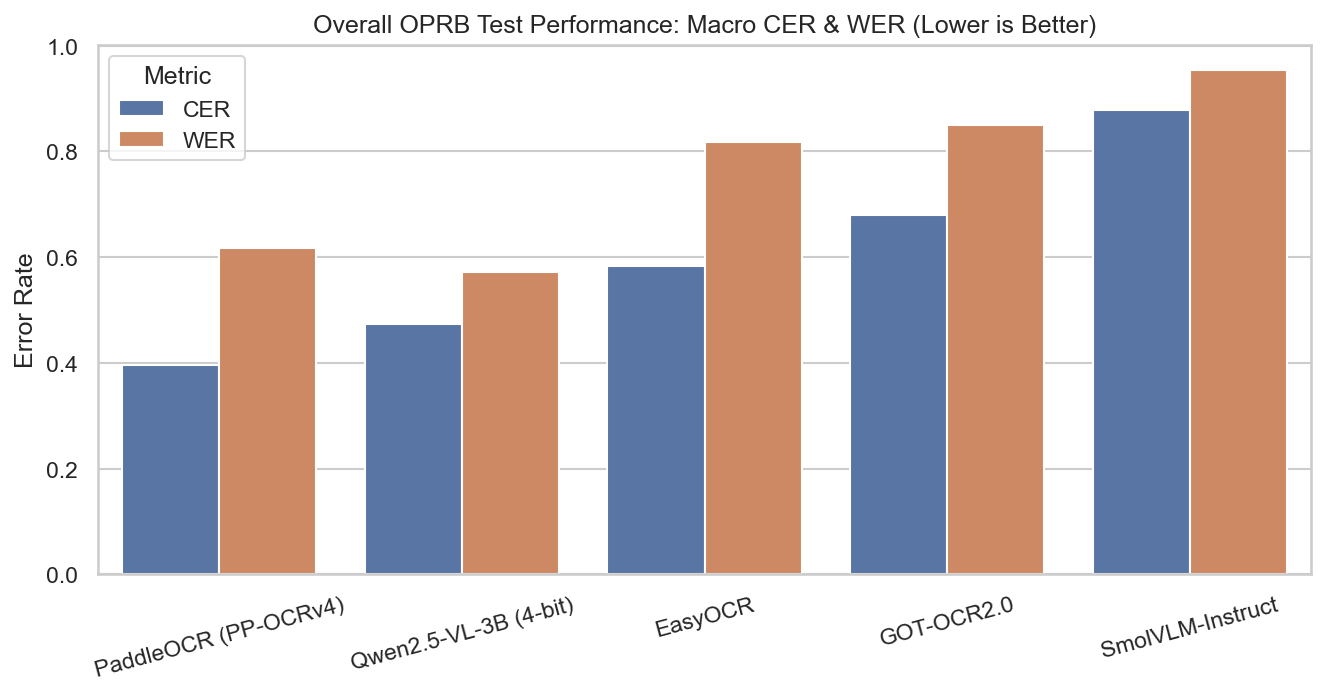

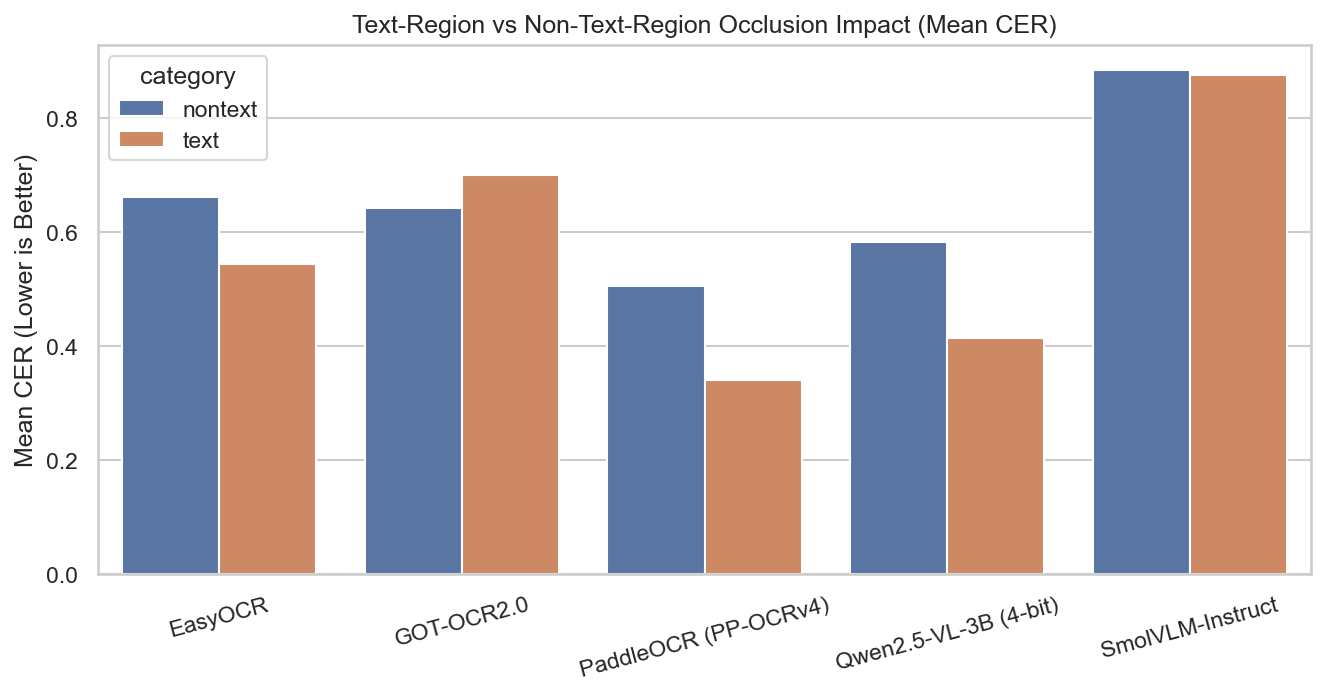

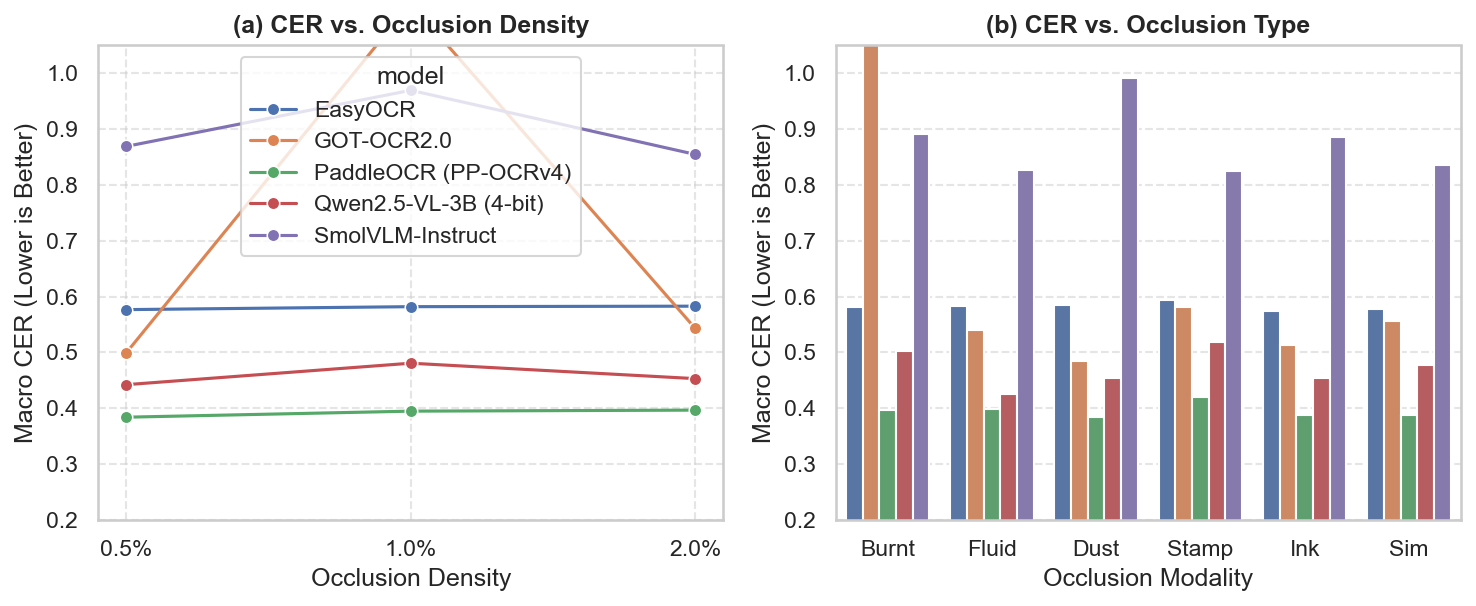

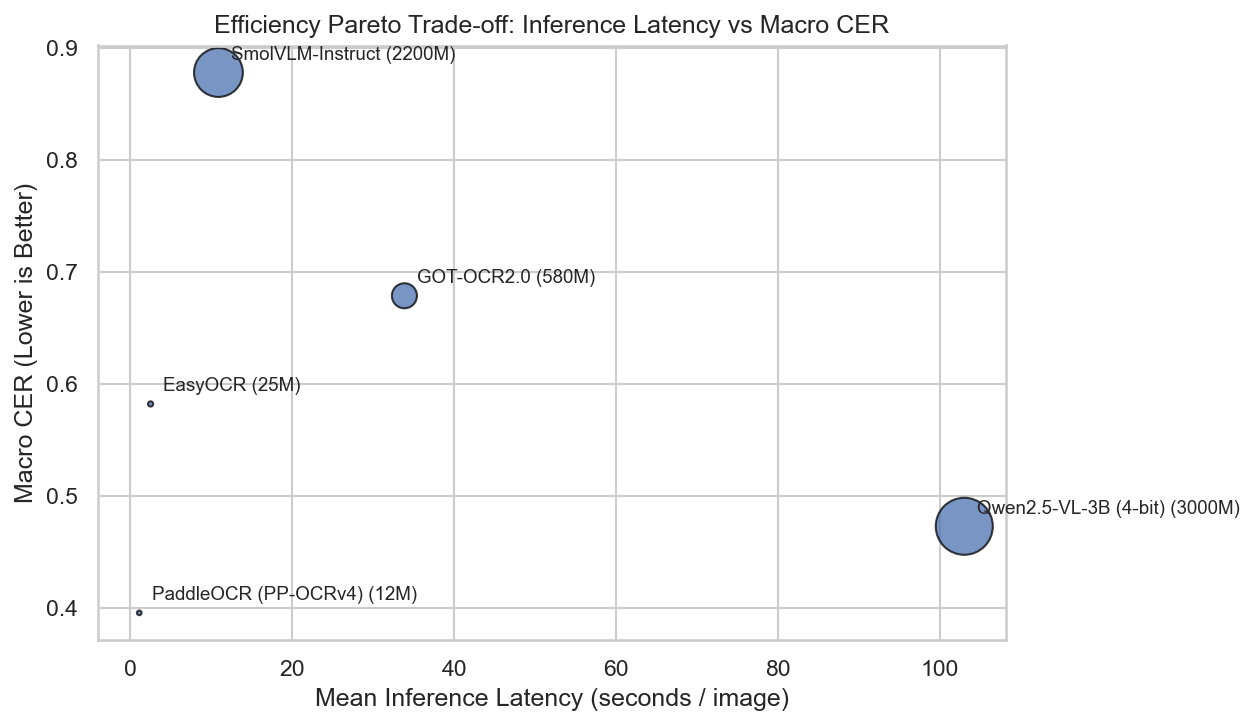

In [4]:
# Figure 1: Overall Performance (CER & WER across all 5 models)
fig, ax = plt.subplots(figsize=(9, 4.8))
melted_overall = summary_df.melt(
    id_vars="model", value_vars=["macro_cer", "macro_wer"],
    var_name="Metric", value_name="Error Rate"
)
melted_overall["Metric"] = melted_overall["Metric"].map({"macro_cer": "CER", "macro_wer": "WER"})
sns.barplot(data=melted_overall, x="model", y="Error Rate", hue="Metric", ax=ax)
ax.set_title("Overall OPRB Test Performance: Macro CER & WER (Lower is Better)")
ax.set_xlabel("")
ax.set_ylabel("Error Rate")
ax.tick_params(axis="x", rotation=15)
plt.tight_layout()
plt.savefig(OUTPUT_DIR / "fig1_overall_performance.png", dpi=300)
plt.show()

# Figure 2: Text-Region vs Non-Text-Region Occlusion Degradation
cat_df = (
    all_df.groupby(["model", "category"], as_index=False)
    .agg(mean_cer=("cer", "mean"), mean_wer=("wer", "mean"))
)
fig, ax = plt.subplots(figsize=(9, 4.8))
sns.barplot(data=cat_df, x="model", y="mean_cer", hue="category", ax=ax)
ax.set_title("Text-Region vs Non-Text-Region Occlusion Impact (Mean CER)")
ax.set_xlabel("")
ax.set_ylabel("Mean CER (Lower is Better)")
ax.tick_params(axis="x", rotation=15)
plt.tight_layout()
plt.savefig(OUTPUT_DIR / "fig2_text_vs_nontext.png", dpi=300)
plt.show()

# Figure 3: Robustness across Occlusion Densities & Occlusion Types
import re
def extract_clean_meta(stem):
    m_dens = re.search(r"(\d+p\d+|\d+)pct", str(stem))
    dens = f"{m_dens.group(1).replace('p', '.')}%" if m_dens else None
    raw_type = str(stem).split("__")[0]
    type_map = {"White_Burnt": "Burnt", "White_Whitener": "Fluid", "Through_Dust": "Dust", "Through_Stamp": "Stamp", "Black_Ink": "Ink", "Sim": "Sim"}
    return type_map.get(raw_type, raw_type), dens

meta_tuples = [extract_clean_meta(s) for s in all_df["sample_id"]]
all_df["clean_type"] = [t[0] for t in meta_tuples]
all_df["clean_density"] = [t[1] for t in meta_tuples]

fig, axes = plt.subplots(1, 2, figsize=(10, 4.2), dpi=150)
dens_valid = all_df[all_df["clean_density"].isin(["0.5%", "1.0%", "2.0%"])].copy()
dens_summary = dens_valid.groupby(["model", "clean_density"], as_index=False)["cer"].mean()
dens_summary["dens_num"] = dens_summary["clean_density"].str.replace("%", "").astype(float)
dens_summary = dens_summary.sort_values(["model", "dens_num"])
sns.lineplot(data=dens_summary, x="clean_density", y="cer", hue="model", marker="o", ax=axes[0])
axes[0].set_title("(a) CER vs. Occlusion Density", fontweight="bold")
axes[0].set_xlabel("Occlusion Density")
axes[0].set_ylabel("Macro CER (Lower is Better)")
axes[0].set_ylim(0.2, 1.05)
axes[0].grid(True, linestyle="--", alpha=0.5)

type_order = ["Burnt", "Fluid", "Dust", "Stamp", "Ink", "Sim"]
type_summary = all_df.groupby(["model", "clean_type"], as_index=False)["cer"].mean()
sns.barplot(data=type_summary, x="clean_type", y="cer", hue="model", order=type_order, ax=axes[1])
axes[1].set_title("(b) CER vs. Occlusion Type", fontweight="bold")
axes[1].set_xlabel("Occlusion Modality")
axes[1].set_ylabel("Macro CER (Lower is Better)")
axes[1].set_ylim(0.2, 1.05)
axes[1].grid(True, linestyle="--", alpha=0.5, axis="y")
if axes[1].legend_:
    axes[1].legend_.remove()

plt.tight_layout()
plt.savefig(OUTPUT_DIR / "fig3_occlusion_robustness.png", dpi=300)
plt.show()

# Figure 4: Pareto Trade-off (Latency vs CER, bubble size ~ parameter count)
fig, ax = plt.subplots(figsize=(8.5, 5))
scatter = ax.scatter(
    summary_df["mean_latency_sec"],
    summary_df["macro_cer"],
    s=summary_df["params_m"].clip(lower=20) * 0.25,
    alpha=0.75,
    edgecolors="black",
    linewidths=1.0,
)
for _, row in summary_df.iterrows():
    ax.annotate(
        f"{row['model']} ({row['params_m']:.0f}M)",
        (row["mean_latency_sec"], row["macro_cer"]),
        textcoords="offset points",
        xytext=(6, 6),
        fontsize=9,
    )
ax.set_title("Efficiency Pareto Trade-off: Inference Latency vs Macro CER")
ax.set_xlabel("Mean Inference Latency (seconds / image)")
ax.set_ylabel("Macro CER (Lower is Better)")
plt.tight_layout()
plt.savefig(OUTPUT_DIR / "fig4_pareto_tradeoff.png", dpi=300)
plt.show()

## 5. Automated Qualitative Case Studies (2 Best + 2 Severe Failure)

In [5]:
pivot_cer = all_df.pivot_table(index="sample_id", columns="model", values="cer", aggfunc="mean")
meta_cols = (
    all_df[["sample_id", "category", "occlusion_type", "occlusion_density", "ground_truth"]]
    .drop_duplicates("sample_id")
    .set_index("sample_id")
)
case_pool = meta_cols.join(pivot_cer)
case_pool["avg_cer"] = pivot_cer.mean(axis=1)

best_ids = case_pool.nsmallest(2, "avg_cer").index.tolist()
dense_text = case_pool[case_pool["category"] == "text"]
worst_ids = (dense_text if len(dense_text) >= 2 else case_pool).nlargest(2, "avg_cer").index.tolist()
selected_ids = best_ids + worst_ids

cases_df = all_df[all_df["sample_id"].isin(selected_ids)].copy()
cases_df["case_group"] = np.where(cases_df["sample_id"].isin(best_ids), "best_transcription", "severe_failure")
cases_df.to_csv(OUTPUT_DIR / "qualitative_case_studies.csv", index=False)

md_lines = ["# Qualitative Case Studies\n"]
for sid in selected_ids:
    sub = cases_df[cases_df["sample_id"] == sid]
    first = sub.iloc[0]
    md_lines.append(f"## `{sid}` ({first['case_group']} | {first['category']} | {first['occlusion_type']} @ {first['occlusion_density']})")
    md_lines.append(f"**Ground Truth (first 300 chars):** {str(first['ground_truth'])[:300]}\n")
    for _, r in sub.iterrows():
        md_lines.append(f"- **{r['model']}** (CER={r['cer']:.3f}, WER={r['wer']:.3f}): {str(r['prediction'])[:250]}")
    md_lines.append("")

(OUTPUT_DIR / "qualitative_case_studies.md").write_text("\n".join(md_lines), encoding="utf-8")
print("Exported qualitative_case_studies.csv and qualitative_case_studies.md")
display(cases_df[["case_group", "sample_id", "category", "occlusion_type", "occlusion_density", "model", "cer", "wer"]])

Exported qualitative_case_studies.csv and qualitative_case_studies.md
               case_group  ...         wer
711        severe_failure  ...    1.000000
1447       severe_failure  ...   32.000000
2016       severe_failure  ...  256.000000
2494   best_transcription  ...    0.015060
2502   best_transcription  ...    0.010363
3655       severe_failure  ...    1.000000
4814       severe_failure  ...    1.000000
5383       severe_failure  ...    0.000000
5861   best_transcription  ...    0.400602
5869   best_transcription  ...    0.261658
13814      severe_failure  ...    1.000000
14383      severe_failure  ...    1.000000
14861  best_transcription  ...    0.135542
14869  best_transcription  ...    0.401554

[14 rows x 8 columns]
